In [1]:
import random
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit

from ml.data_io import iter_signals_and_targets, iter_signals_only
from ml.features import add_epoch_drift, build_feature_df
from ml.model import fit_decoder_context, predict_with_decoder, train_xgboost

In [2]:
@dataclass
class Config:
    bundle_dir: Path = Path("data")
    sf: int = 100  # sampling rate
    samples_per_epoch: int = 30 * 100  # 30s epochs
    stage_names: list[str] = field(default_factory=lambda: ["Wake", "N1", "N2", "N3", "REM"])
    # Feature params
    load_precomputed_features: bool = False
    bands: dict[str, tuple[float, float]] = field(
        default_factory=lambda: {
            "slow_delta": (0.5, 2),
            "delta": (2, 4),
            "theta": (4, 8),
            "alpha": (8, 12),
            "sigma": (12, 15),
            "beta": (15, 30),
        },
    )
    add_epoch_drift_window: int = 2
    add_epoch_drift_symmetric: bool = True
    # model params
    num_classes: int = 5
    eta: float = 0.03
    max_depth: int = 4
    subsample: float = 0.8
    colsample_bytree: float = 0.8
    num_boost_round: int = 500
    seed: int = 42
    smoothing_window: int = 1
    n_jobs: int = 4
    # decoding
    decoder: str = "hmm"  # options: "argmax", "smooth", "hmm"
    hmm_alpha: float = 1.0
    # cross-validation params
    cv_n_splits: int = 5
    # choose whether to create submission predictions
    create_submission: bool = False
    submission_name: str = "submission.csv"

In [3]:
config = Config(bundle_dir = Path("../data"))

In [4]:
raw_train_data = iter_signals_and_targets(config.bundle_dir, split="train")
raw_test_data = iter_signals_only(config.bundle_dir, split="test")
raw_train_data = iter_signals_and_targets(config.bundle_dir, split="train")
raw_test_data = iter_signals_only(config.bundle_dir, split="test")

In [5]:
df_train = build_feature_df(raw_train_data, with_labels=True, config=config)
df_train = add_epoch_drift(
    df_train,
    window=config.add_epoch_drift_window,
    symmetric=config.add_epoch_drift_symmetric,
)

In [6]:
df_train

,patient_id,epoch_idx,identifier,mean,std,ptp,slow_delta,delta,theta,alpha,...,sigma_burst_frac,spec_entropy,log_delta_theta,log_alpha_beta,theta_dominance,beta_silence,label,epoch_drift_prev,epoch_drift_next,epoch_drift_mean
0,0,0,0,-0.002056,0.281659,1.955991,-4.520100,-5.970237,-5.368990,-2.903019,...,0.036200,3.710827,-0.601247,2.759551,-2.527367,-0.293580,0,0.000000,0.011959,0.005980
1,0,1,1,0.000493,0.262859,1.850865,-4.547810,-6.007101,-5.630204,-3.162292,...,0.035133,3.624036,-0.376896,2.752184,-2.529749,-0.284272,0,0.000000,0.010574,0.005287
2,0,2,2,0.000763,0.261666,1.680616,-4.925597,-5.917502,-5.565328,-3.336606,...,0.045067,3.490024,-0.352174,2.774341,-2.289244,-0.545619,0,0.003025,0.012279,0.007652
3,0,3,3,-0.001942,0.241289,1.666237,-5.221362,-6.146073,-5.819474,-3.343122,...,0.042133,3.488085,-0.326599,2.767822,-2.537258,-0.291470,0,0.011959,0.013904,0.012932
4,0,4,4,0.002725,0.240692,1.793912,-4.713387,-5.844990,-5.661986,-3.598101,...,0.044467,3.551208,-0.183004,2.557121,-2.138555,-0.493236,0,0.010574,0.017791,0.014183
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7428,7,977,70977,0.000615,0.570573,6.274639,-2.059146,-3.144259,-3.555673,-3.289054,...,0.037200,3.962634,0.411414,0.053261,-0.933490,0.213357,0,0.454698,0.251684,0.353191
7429,7,978,70978,0.000891,0.985119,10.758858,-1.192349,-1.859668,-2.987002,-2.994042,...,0.040200,3.612344,1.127334,0.038533,-0.667026,-0.045573,0,0.291540,0.193473,0.242507
7430,7,979,70979,0.000443,3.134613,30.283478,1.515543,-0.234421,-1.476548,-1.790474,...,0.050933,2.745929,1.242127,-0.435103,-0.620253,0.121177,0,0.084006,0.109842,0.096924
7431,7,980,70980,-0.016104,2.287064,20.639336,0.571515,-0.591914,-1.732648,-2.285462,...,0.041400,2.993818,1.140734,-0.299185,-0.301073,-0.253629,0,0.251684,0.092133,0.171908


In [ ]:
X = df_train.drop(columns=["label", "identifier", "patient_id", "epoch_idx"])
y = df_train["label"]
groups = df_train["patient_id"].to_numpy()

In [8]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=config.seed)
tr_idx, va_idx = next(gss.split(X, y, groups))

X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]


model = train_xgboost(X_tr, y_tr, config)
ctx = fit_decoder_context(
            y_tr,
            df_train.iloc[tr_idx],
            config,
        )

y_pred = predict_with_decoder(
    model,
    X_va,
    df_train.iloc[va_idx],
    config,
    ctx,
)
f1 = f1_score(y_va, y_pred, average="macro")

print(f"Macro-F1: {f1:.4f}")
print(
    classification_report(
        y_va,
        y_pred,
        target_names=config.stage_names,
        digits=3,
    ),
)

Macro-F1: 0.7052
              precision    recall  f1-score   support

        Wake      0.904     0.915     0.909       422
          N1      0.188     0.424     0.260        85
          N2      0.859     0.912     0.885       844
          N3      0.906     0.993     0.948       283
         REM      0.874     0.374     0.524       334

    accuracy                          0.812      1968
   macro avg      0.746     0.724     0.705      1968
weighted avg      0.849     0.812     0.811      1968



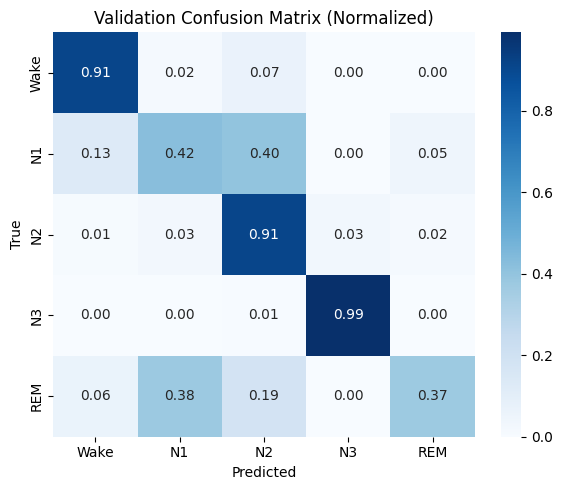

In [9]:
cm = confusion_matrix(y_va, y_pred, normalize="true")

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=config.stage_names,
    yticklabels=config.stage_names,
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Validation Confusion Matrix (Normalized)")
plt.tight_layout()